# Лабораторная работа №3: Свойства оценок, полученных методом моментов

1. Метод моментов (ММ) для равномерного распределения $U[a, b]$, генеральное распределение — $U[0, 1]$. График зависимости оценок от размера выборки.
2. Обобщённый метод моментов (ОММ) для $U[a, b]$ с 3, 5, 7 моментами. График зависимости оценок от размера выборки. Веса ОММ, снижающие дисперсию по сравнению с ММ.
3. СКО оценок из пп. 1–2 в зависимости от размера выборки (по $10^3$ выборкам). Выводы.
4. Пункты 1–3 для экспоненциального распределения $\mathrm{Exp}(\lambda)$, генеральное распределение — $\mathrm{Exp}(1)$.

## Теория

**Метод моментов.** Для распределения с параметром $\theta \in \mathbb{R}^p$ берём $p$ теоретических моментов
$\mu_j(\theta) = \mathbb{E}_\theta X^j$, приравниваем их к выборочным $\hat m_j = \frac1n \sum_{i=1}^n X_i^j$
и решаем систему $\mu_j(\theta) = \hat m_j,\ j = 1, \dots, p$.

**Обобщённый метод моментов.** Если моментов больше, чем параметров ($k > p$), система в общем случае несовместна.
Тогда минимизируем квадратичную форму от невязок
$$
\hat\theta = \arg\min_\theta\ g(\theta)^\top W\, g(\theta), \qquad g_j(\theta) = \hat m_j - \mu_j(\theta),\ j = 1, \dots, k,
$$
где $W$ — положительно определённая матрица весов. Минимум ищем методом Гаусса–Ньютона.

Асимптотически $\sqrt n(\hat\theta - \theta) \to N(0, V_W)$, где
$$
V_W = (G^\top W G)^{-1} G^\top W S W G\, (G^\top W G)^{-1}, \qquad
G = \frac{\partial \mu}{\partial \theta^\top}, \qquad
S_{jl} = \operatorname{cov}(X^j, X^l) = \mu_{j+l} - \mu_j \mu_l .
$$
Наименьшую асимптотическую дисперсию даёт $W = S^{-1}$: тогда $V_{\mathrm{opt}} = (G^\top S^{-1} G)^{-1} \preceq V_W$ при любой $W$.

In [ ]:
from math import factorial

import numpy as np
import matplotlib.pyplot as plt

SEED = 42
N_MC = 10**3                     # число выборок для оценки СКО
N_MAX = 10**4                    # максимальный размер выборки
K_LIST = [3, 5, 7]               # число моментов в ОММ
N_TRAJ = np.unique(np.logspace(1, 4, 60).astype(int))           # размеры для графиков оценок
N_MC_SIZES = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]  # размеры для СКО

plt.rcParams['figure.dpi'] = 110

## Общие функции

- `raw_moments` — выборочные начальные моменты $\hat m_1, \dots, \hat m_k$ (по последней оси, т.е. сразу для многих выборок);
- `gmm_solve` — векторизованный метод Гаусса–Ньютона с дроблением шага: минимизирует $g^\top W g$ сразу для набора выборок;
- `asym_cov` — асимптотическая ковариационная матрица $V_W$.

In [2]:
def raw_moments(x, k):
    out = np.empty(x.shape[:-1] + (k,))
    p = np.ones_like(x)
    for j in range(k):
        p = p * x
        out[..., j] = p.mean(axis=-1)
    return out


def prefix_moments(x, sizes, k):
    """Моменты по первым n элементам одной выборки для каждого n из sizes."""
    pw = x[None, :] ** np.arange(1, k + 1)[:, None]
    cs = np.cumsum(pw, axis=1)
    sizes = np.asarray(sizes)
    return (cs[:, sizes - 1] / sizes).T


def gmm_solve(m, mu_f, jac_f, theta0, W, valid, n_iter=100, tol=1e-10):
    """
    m       — выборочные моменты, shape (R, k)
    mu_f    — теоретические моменты mu_f(theta, k) -> (R, k)
    jac_f   — якобиан jac_f(theta, k) -> (R, k, p)
    theta0  — начальное приближение, shape (R, p)
    W       — веса, shape (k, k) или (R, k, k)
    valid   — допустимость параметров valid(theta) -> (R,) bool
    """
    k = m.shape[1]
    th = theta0.astype(float).copy()
    W = np.broadcast_to(W, (len(th), k, k))

    def Q(t, rows):
        g = m[rows] - mu_f(t, k)
        return (g * (W[rows] @ g[..., None])[..., 0]).sum(axis=1)

    q = Q(th, slice(None))
    active = np.arange(len(th))
    for _ in range(n_iter):
        if active.size == 0:
            break
        t0, Wa = th[active], W[active]
        g = m[active] - mu_f(t0, k)
        J = jac_f(t0, k)
        JtW = J.transpose(0, 2, 1) @ Wa
        step = np.linalg.solve(JtW @ J, JtW @ g[..., None])[..., 0]

        lam = np.ones(len(active))
        pending = np.arange(len(active))
        new = t0 + step
        qn = np.full(len(active), np.inf)
        for _ in range(30):
            cand = t0[pending] + lam[pending, None] * step[pending]
            ok = valid(cand)
            qc = np.full(len(pending), np.inf)
            if ok.any():
                qc[ok] = Q(cand[ok], active[pending[ok]])
            good = qc <= q[active[pending]]
            new[pending[good]] = cand[good]
            qn[pending[good]] = qc[good]
            pending = pending[~good]
            if pending.size == 0:
                break
            lam[pending] /= 2

        moved = np.isfinite(qn)
        th[active[moved]] = new[moved]
        q[active[moved]] = qn[moved]
        delta = np.abs(lam[:, None] * step).max(axis=1)
        active = active[moved & (delta > tol)]
    return th


def asym_cov(G, S, W):
    A = np.linalg.inv(G.T @ W @ G)
    return A @ G.T @ W @ S @ W @ G @ A

### Общая схема экспериментов

Для каждого распределения считаем следующие оценки:

- **ММ** — классический метод моментов (столько моментов, сколько параметров);
- **ОММ, $W = I$** — 3, 5, 7 моментов с единичными весами;
- **ОММ, $W = S^{-1}$** — 3, 5, 7 моментов с оптимальными весами (двухшаговый ОММ, см. ниже).

Функция `estimate_all` по массиву выборочных моментов возвращает все оценки; она же используется и для графиков «оценка от $n$», и для Монте-Карло.

In [3]:
def estimate_all(m, model):
    """m — выборочные моменты (R, 7). Возвращает словарь {название: оценки (R, p)}."""
    mm = model['mm'](m)
    res = {'ММ': mm}
    for k in K_LIST:
        mk = m[:, :k]
        res[f'ОММ, k={k}, W=I'] = gmm_solve(mk, model['mu'], model['jac'], mm, np.eye(k), model['valid'])
        W_opt = np.linalg.inv(model['S'](mm, k))
        res[f'ОММ, k={k}, W=S⁻¹'] = gmm_solve(mk, model['mu'], model['jac'], mm, W_opt, model['valid'])
    return res


STYLE = {
    'ММ': dict(color='black', lw=2),
    'ОММ, k=3, W=I': dict(color='tab:blue', ls='--'),
    'ОММ, k=5, W=I': dict(color='tab:orange', ls='--'),
    'ОММ, k=7, W=I': dict(color='tab:green', ls='--'),
    'ОММ, k=3, W=S⁻¹': dict(color='tab:blue'),
    'ОММ, k=5, W=S⁻¹': dict(color='tab:orange'),
    'ОММ, k=7, W=S⁻¹': dict(color='tab:green'),
}
MARKER = {'ММ': dict(marker='o', ms=9, mfc='none'),
          **{f'ОММ, k={k}, W={w}': dict(marker=mk, ms=5)
             for k, mk in zip(K_LIST, ['s', '^', 'x']) for w in ['I', 'S⁻¹']}}


def plot_trajectories(sizes, res, names, param_names, true_vals, title):
    p = len(param_names)
    fig, axes = plt.subplots(1, p, figsize=(6.5 * p, 4.2), squeeze=False)
    for i in range(p):
        ax = axes[0, i]
        for name in names:
            ax.plot(sizes, res[name][:, i], label=name, **STYLE[name])
        ax.axhline(true_vals[i], color='red', lw=1, ls=':', label='истинное значение')
        ax.set_xscale('log')
        ax.set_xlabel('n')
        ax.set_ylabel(param_names[i])
        ax.set_title(f'{title}: оценка {param_names[i]}')
        ax.grid(True, which='both', alpha=0.3)
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def monte_carlo(model, sampler, sizes, n_mc, seed):
    rng = np.random.default_rng(seed)
    out = {}
    for n in sizes:
        x = sampler(rng, (n_mc, n))
        est = estimate_all(raw_moments(x, max(K_LIST)), model)
        out[n] = {name: (v.mean(axis=0), v.std(axis=0, ddof=1)) for name, v in est.items()}
    return out


def plot_std(mc, sizes, names, param_names, asym_sd, title):
    p = len(param_names)
    fig, axes = plt.subplots(1, p, figsize=(6.5 * p, 4.5), squeeze=False)
    ns = np.array(sizes, float)
    for i in range(p):
        ax = axes[0, i]
        for name in names:
            sd = [mc[n][name][1][i] for n in sizes]
            ax.plot(ns, sd, label=name, **STYLE[name], **MARKER[name])
            if name in asym_sd:
                ax.plot(ns, asym_sd[name][i] / np.sqrt(ns), color=STYLE[name]['color'],
                        lw=0.8, ls=':', alpha=0.8)
        ax.plot([], [], color='gray', lw=0.8, ls=':', label='асимптотика σ/√n')
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel('n')
        ax.set_ylabel('СКО')
        ax.set_title(f'{title}: СКО оценки {param_names[i]}')
        ax.grid(True, which='both', alpha=0.3)
    axes[0, 0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def print_mc_table(mc, sizes, names, param_names, true_vals):
    for i, pn in enumerate(param_names):
        print(f'\nСКО оценки {pn} (в скобках — смещение)')
        print(f'{"метод":<17}' + ''.join(f'{n:>17d}' for n in sizes))
        for name in names:
            row = ''.join(f'{mc[n][name][1][i]:>8.4f} ({mc[n][name][0][i] - true_vals[i]:+.4f})'
                          for n in sizes)
            print(f'{name:<17}{row}')

---
# Часть I. Равномерное распределение $U[a, b]$

Начальные моменты:
$$
\mu_j(a, b) = \mathbb{E} X^j = \frac{b^{j+1} - a^{j+1}}{(j+1)(b-a)} = \frac{1}{j+1}\sum_{i=0}^{j} a^{j-i} b^{i}.
$$
Для вычислений удобна рекуррентная форма $h_j = b\,h_{j-1} + a^j$, $h_0 = 1$, $\mu_j = h_j/(j+1)$ — она не имеет особенности при $a = b$.
Производные по $a$ и $b$ считаются той же рекурсией.

## 1. Метод моментов

Два параметра — два момента: $\mathbb{E}X = \frac{a+b}{2}$, $\mathbb{D}X = \frac{(b-a)^2}{12}$. Отсюда
$$
\hat a = \hat m_1 - \sqrt{3 \hat s^2}, \qquad \hat b = \hat m_1 + \sqrt{3 \hat s^2}, \qquad \hat s^2 = \hat m_2 - \hat m_1^2 .
$$

In [4]:
def unif_mu(theta, k):
    a, b = theta[:, 0], theta[:, 1]
    out = np.empty((len(theta), k))
    h, aj = np.ones_like(a), np.ones_like(a)
    for j in range(1, k + 1):
        aj = aj * a
        h = b * h + aj
        out[:, j - 1] = h / (j + 1)
    return out


def unif_jac(theta, k):
    a, b = theta[:, 0], theta[:, 1]
    J = np.empty((len(theta), k, 2))
    h, ha, hb = np.ones_like(a), np.zeros_like(a), np.zeros_like(a)
    aj = np.ones_like(a)
    for j in range(1, k + 1):
        ha = b * ha + j * aj
        hb = h + b * hb
        aj = aj * a
        h = b * h + aj
        J[:, j - 1, 0] = ha / (j + 1)
        J[:, j - 1, 1] = hb / (j + 1)
    return J


def unif_S(theta, k):
    mu = unif_mu(theta, 2 * k)
    idx = np.arange(1, k + 1)
    m = mu[:, idx - 1]
    return mu[:, idx[:, None] + idx[None, :] - 1] - m[:, :, None] * m[:, None, :]


def unif_mm(m):
    s = np.sqrt(3 * np.maximum(m[:, 1] - m[:, 0] ** 2, 0))
    return np.stack([m[:, 0] - s, m[:, 0] + s], axis=1)


UNIF = dict(mu=unif_mu, jac=unif_jac, S=unif_S, mm=unif_mm,
            valid=lambda t: t[:, 1] > t[:, 0])
UNIF_TRUE = np.array([0.0, 1.0])
UNIF_PARAMS = ['a', 'b']

# проверка: моменты и якобиан против прямой формулы и численного дифференцирования
th = np.array([[0.3, 1.7]])
j = np.arange(1, 8)
direct = (1.7 ** (j + 1) - 0.3 ** (j + 1)) / ((j + 1) * 1.4)
eps = 1e-6
num_jac = np.stack([(unif_mu(th + eps * e, 7) - unif_mu(th - eps * e, 7))[0] / (2 * eps)
                    for e in np.eye(2)], axis=1)
print('макс. ошибка моментов :', np.abs(unif_mu(th, 7)[0] - direct).max())
print('макс. ошибка якобиана :', np.abs(unif_jac(th, 7)[0] - num_jac).max())

макс. ошибка моментов : 8.881784197001252e-16
макс. ошибка якобиана : 2.270720500519019e-09


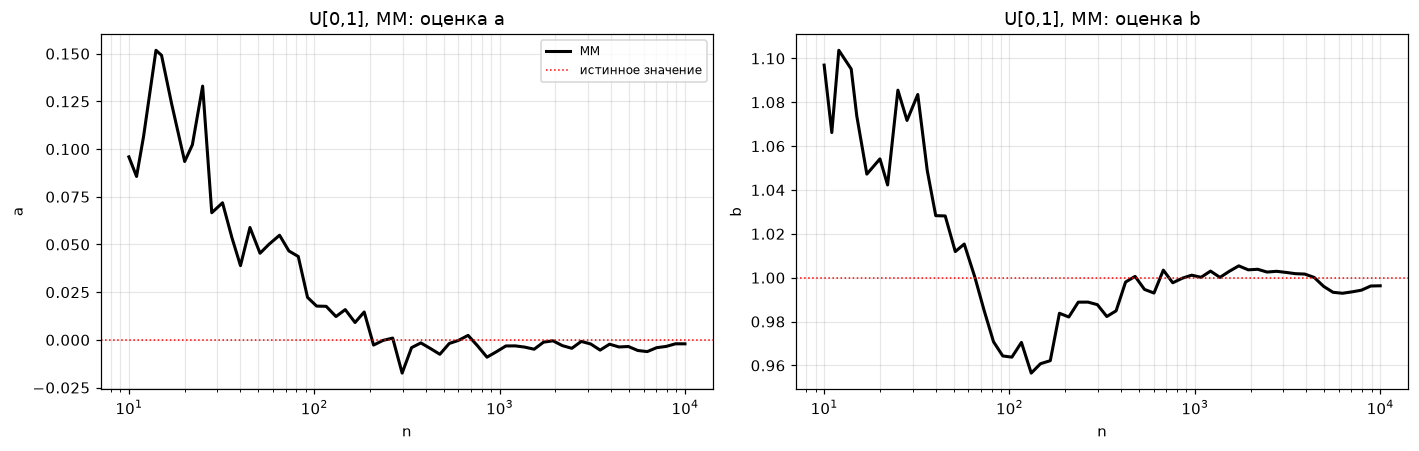

In [5]:
rng = np.random.default_rng(SEED)
x_unif = rng.uniform(0, 1, N_MAX)
m_traj_unif = prefix_moments(x_unif, N_TRAJ, max(K_LIST))
traj_unif = estimate_all(m_traj_unif, UNIF)

plot_trajectories(N_TRAJ, traj_unif, ['ММ'], UNIF_PARAMS, UNIF_TRUE, 'U[0,1], ММ')

## 2. Обобщённый метод моментов

Используем первые $k = 3, 5, 7$ моментов. Начальное приближение для Гаусса–Ньютона — оценка ММ.

### Выбор весов

1. **$W = I$** — «наивный» вариант: все невязки равноправны.
   Для $U[0,1]$ высокие моменты $\mathbb{E}X^j = \frac{1}{j+1}$ определяются в основном значениями около правой границы,
   поэтому с ростом $k$ оценка $b$ уточняется, а оценка $a$ — ухудшается.
2. **$W = S^{-1}$ (предлагаемые веса)** — обратная ковариационная матрица моментных функций
   $S_{jl} = \operatorname{cov}(X^j, X^l) = \mu_{j+l}(\theta) - \mu_j(\theta)\mu_l(\theta)$.
   Сильно коррелированные и сильно шумящие моменты получают меньший вес. Это оптимальные веса: $V_{S^{-1}} \preceq V_W$ для любой $W$.
   Кроме того, набор моментов $\{1, \dots, k\}$ содержит $\{1, 2\}$, поэтому $V_{S^{-1}}^{(k)} \preceq V_{\text{ММ}}$,
   и с ростом $k$ асимптотическая дисперсия не растёт.

   $S$ зависит от неизвестного $\theta$, поэтому применяем **двухшаговую схему**:
   шаг 1 — оценка ММ $\hat\theta_0$; шаг 2 — минимизация с $W = S(\hat\theta_0)^{-1}$.
   Используем теоретическую $S(\hat\theta_0)$, а не выборочную ковариацию $X^j$: при малых $n$ выборочная матрица $7\times 7$ плохо обусловлена.

Асимптотические СКО, умноженные на $\sqrt n$, в точке $a = 0,\ b = 1$:

In [6]:
def asym_table(model, theta, param_names):
    th = np.array([theta], float)
    G2, S2 = model['jac'](th, len(theta))[0], model['S'](th, len(theta))[0]
    table = {'ММ': np.sqrt(np.diag(asym_cov(G2, S2, np.eye(len(theta)))))}
    for k in K_LIST:
        G, S = model['jac'](th, k)[0], model['S'](th, k)[0]
        table[f'ОММ, k={k}, W=I'] = np.sqrt(np.diag(asym_cov(G, S, np.eye(k))))
        table[f'ОММ, k={k}, W=S⁻¹'] = np.sqrt(np.diag(asym_cov(G, S, np.linalg.inv(S))))
    print(f'{"метод":<17}' + ''.join(f'{"√n·СКО(" + p + ")":>14}' for p in param_names))
    for name, sd in table.items():
        print(f'{name:<17}' + ''.join(f'{v:>14.4f}' for v in sd))
    return table

asym_unif = asym_table(UNIF, UNIF_TRUE, UNIF_PARAMS)

метод                 √n·СКО(a)     √n·СКО(b)
ММ                       0.3651        0.3651
ОММ, k=3, W=I            0.4104        0.3318
ОММ, k=3, W=S⁻¹          0.2739        0.2739
ОММ, k=5, W=I            0.4745        0.2881
ОММ, k=5, W=S⁻¹          0.1725        0.1725
ОММ, k=7, W=I            0.5197        0.2598
ОММ, k=7, W=S⁻¹          0.1273        0.1273


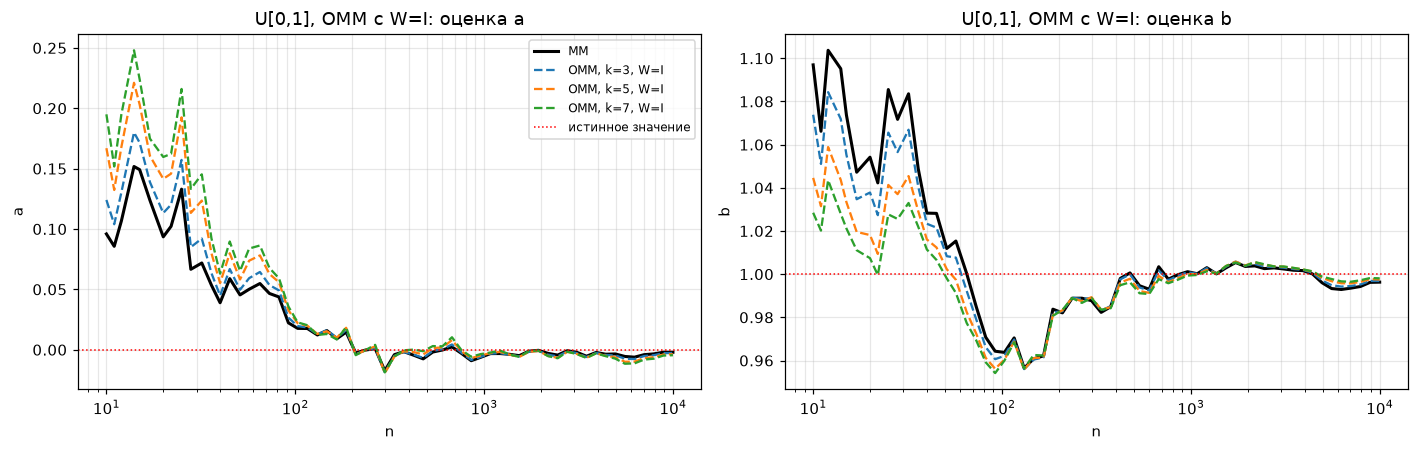

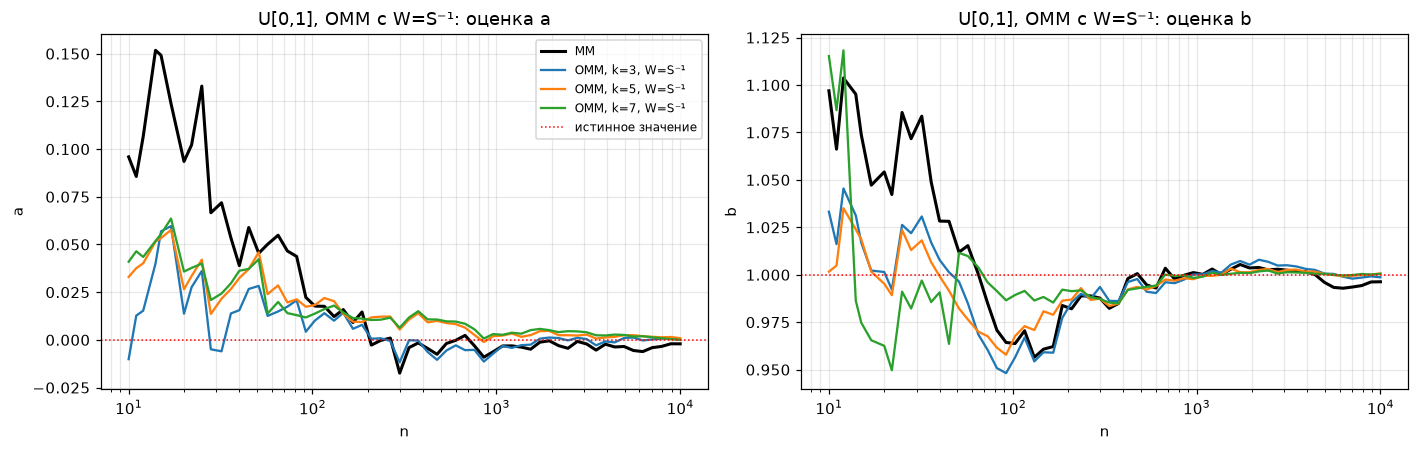

In [7]:
names_I = ['ММ'] + [f'ОММ, k={k}, W=I' for k in K_LIST]
names_opt = ['ММ'] + [f'ОММ, k={k}, W=S⁻¹' for k in K_LIST]

plot_trajectories(N_TRAJ, traj_unif, names_I, UNIF_PARAMS, UNIF_TRUE, 'U[0,1], ОММ с W=I')
plot_trajectories(N_TRAJ, traj_unif, names_opt, UNIF_PARAMS, UNIF_TRUE, 'U[0,1], ОММ с W=S⁻¹')

## 3. СКО оценок

Для каждого $n$ генерируем $N = 10^3$ выборок из $U[0,1]$, на каждой считаем все оценки и находим выборочное СКО
$$
\widehat{\sigma}(\hat\theta) = \sqrt{\frac{1}{N-1}\sum_{r=1}^{N}\bigl(\hat\theta^{(r)} - \overline{\hat\theta}\bigr)^2}.
$$
Пунктиром тех же цветов показана асимптотика $\sigma_{\text{асимп}}/\sqrt n$ из таблицы выше.

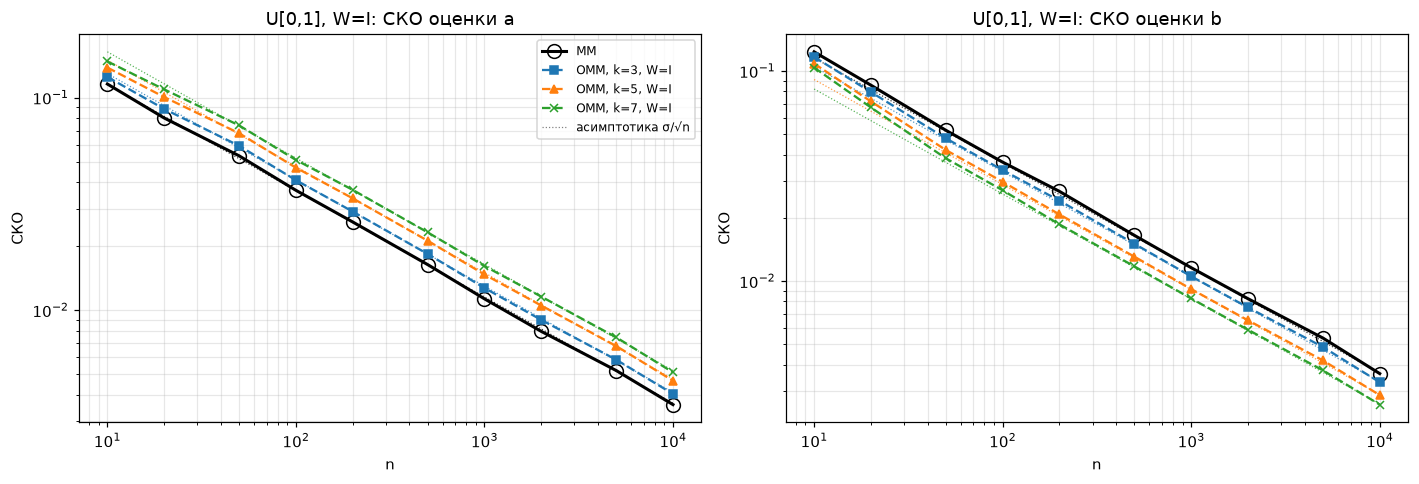

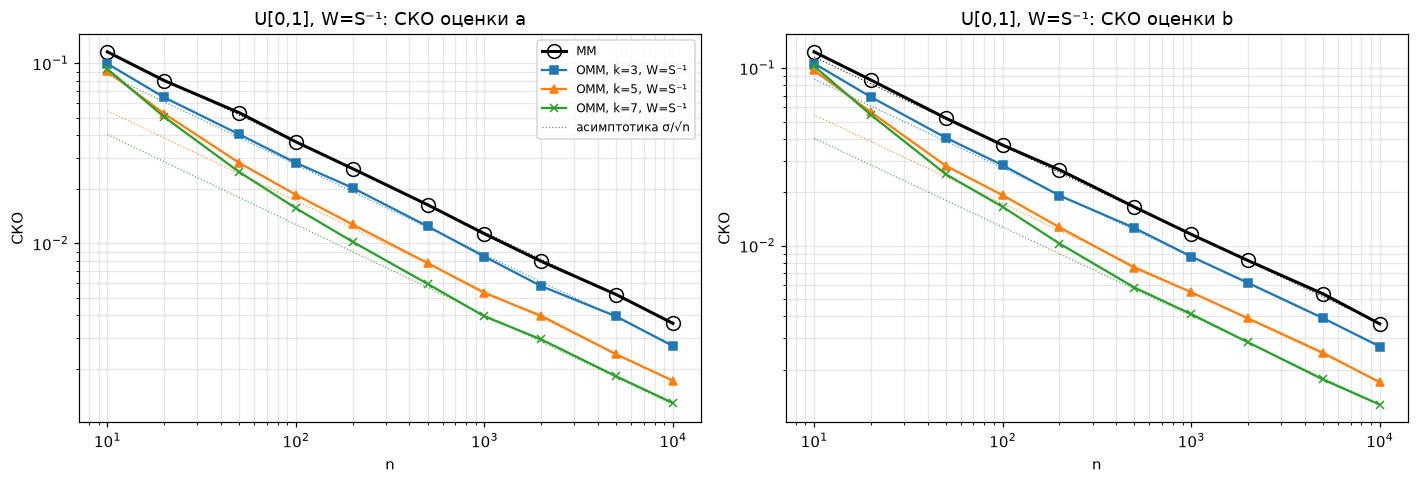

In [8]:
mc_unif = monte_carlo(UNIF, lambda rng, size: rng.uniform(0, 1, size), N_MC_SIZES, N_MC, SEED + 1)

plot_std(mc_unif, N_MC_SIZES, names_I, UNIF_PARAMS, asym_unif, 'U[0,1], W=I')
plot_std(mc_unif, N_MC_SIZES, names_opt, UNIF_PARAMS, asym_unif, 'U[0,1], W=S⁻¹')

In [9]:
print_mc_table(mc_unif, N_MC_SIZES, list(STYLE), UNIF_PARAMS, UNIF_TRUE)


СКО оценки a (в скобках — смещение)
метод                           10               20               50              100              200              500             1000             2000             5000            10000
ММ                 0.1159 (+0.0309)  0.0803 (+0.0167)  0.0532 (+0.0068)  0.0367 (+0.0018)  0.0260 (+0.0017)  0.0164 (+0.0004)  0.0113 (+0.0002)  0.0080 (+0.0002)  0.0052 (+0.0002)  0.0036 (+0.0001)
ОММ, k=3, W=I      0.1252 (+0.0326)  0.0885 (+0.0171)  0.0594 (+0.0071)  0.0409 (+0.0016)  0.0291 (+0.0019)  0.0184 (+0.0003)  0.0127 (+0.0003)  0.0090 (+0.0003)  0.0058 (+0.0002)  0.0040 (+0.0001)
ОММ, k=5, W=I      0.1386 (+0.0374)  0.1007 (+0.0185)  0.0680 (+0.0080)  0.0468 (+0.0015)  0.0336 (+0.0024)  0.0212 (+0.0001)  0.0147 (+0.0005)  0.0105 (+0.0004)  0.0068 (+0.0003)  0.0047 (+0.0001)
ОММ, k=7, W=I      0.1481 (+0.0424)  0.1094 (+0.0200)  0.0740 (+0.0088)  0.0509 (+0.0017)  0.0368 (+0.0028)  0.0232 (+0.0000)  0.0161 (+0.0006)  0.0116 (+0.0005)  0.0075 (+0.0003)  

### Выводы по равномерному распределению

1. **Состоятельность.** Все оценки (ММ и ОММ при любом $k$ и $W$) сходятся к $(a, b) = (0, 1)$ при $n \to \infty$; СКО убывает пропорционально $1/\sqrt n$ (прямые на log-log графиках).
2. **$W = I$ ухудшает оценку $a$ и улучшает $b$.** Высокие моменты чувствительны к правой границе, поэтому с ростом $k$ СКО $\hat b$ падает ($\sqrt n\,\sigma_b$: $0{,}37 \to 0{,}26$), а СКО $\hat a$ растёт ($0{,}37 \to 0{,}52$). По сравнению с ММ единичные веса **не** дают одновременного выигрыша по обоим параметрам.
3. **$W = S^{-1}$ снижает дисперсию обоих параметров.** Уже при $k = 3$ $\sqrt n\,\sigma \approx 0{,}27 < 0{,}37$, при $k = 7$ — $\approx 0{,}13$. Эмпирические СКО по $10^3$ выборкам совпадают с асимптотикой начиная примерно с $n \sim 100$. Это и есть предлагаемые веса: двухшаговый ОММ с $W = S(\hat\theta_0)^{-1}$.
4. При малых $n$ у всех оценок есть смещение («внутрь» интервала для $a$ и $b$), которое исчезает с ростом $n$.

---
# Часть II. Экспоненциальное распределение $\mathrm{Exp}(\lambda)$

Плотность $f(x) = \lambda e^{-\lambda x}$, $x \ge 0$. Один параметр $\lambda$, генеральное распределение — $\mathrm{Exp}(1)$.

Начальные моменты и их производные:
$$
\mu_j(\lambda) = \frac{j!}{\lambda^j}, \qquad \frac{\partial \mu_j}{\partial\lambda} = -\frac{j\cdot j!}{\lambda^{j+1}}, \qquad
S_{jl} = \frac{(j+l)! - j!\,l!}{\lambda^{j+l}} .
$$

## 1. Метод моментов

Один параметр — один момент: $\mathbb{E}X = 1/\lambda$, откуда $\hat\lambda = 1/\bar x$.

In [10]:
FACT = np.array([factorial(j) for j in range(2 * max(K_LIST) + 1)], float)


def exp_mu(theta, k):
    lam = theta[:, :1]
    j = np.arange(1, k + 1)
    return FACT[j] / lam ** j


def exp_jac(theta, k):
    lam = theta[:, :1]
    j = np.arange(1, k + 1)
    return (-j * FACT[j] / lam ** (j + 1))[..., None]


def exp_S(theta, k):
    lam = theta[:, 0][:, None, None]
    j = np.arange(1, k + 1)
    jl = j[:, None] + j[None, :]
    return (FACT[jl] - FACT[j][:, None] * FACT[j][None, :]) / lam ** jl


def exp_mm(m):
    return 1.0 / m[:, :1]


EXP = dict(mu=exp_mu, jac=exp_jac, S=exp_S, mm=exp_mm, valid=lambda t: t[:, 0] > 0)
EXP_TRUE = np.array([1.0])
EXP_PARAMS = ['λ']

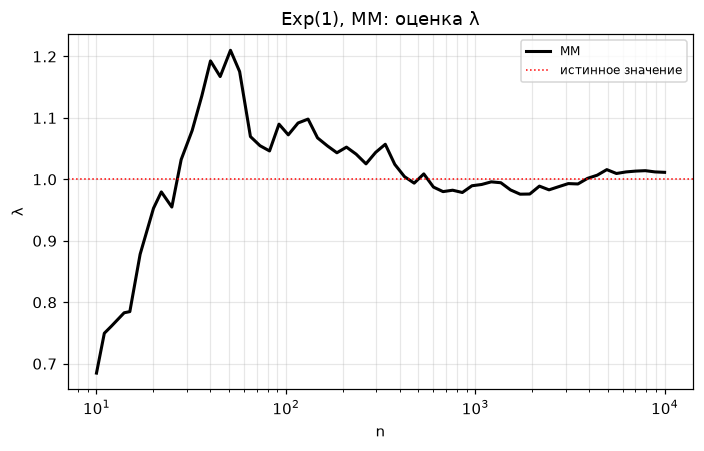

In [11]:
rng = np.random.default_rng(SEED)
x_exp = rng.exponential(1.0, N_MAX)
m_traj_exp = prefix_moments(x_exp, N_TRAJ, max(K_LIST))
traj_exp = estimate_all(m_traj_exp, EXP)

plot_trajectories(N_TRAJ, traj_exp, ['ММ'], EXP_PARAMS, EXP_TRUE, 'Exp(1), ММ')

## 2. Обобщённый метод моментов

Те же два варианта весов: $W = I$ и двухшаговый $W = S(\hat\lambda_0)^{-1}$, $\hat\lambda_0 = 1/\bar x$.

Здесь ситуация принципиально иная, чем у равномерного распределения:

- $\bar x$ — достаточная статистика, а $\hat\lambda = 1/\bar x$ совпадает с оценкой максимального правдоподобия и асимптотически
  достигает границы Рао–Крамера $\lambda^2/n$. **Никакие веса не могут асимптотически уменьшить её дисперсию.**
- Оптимальные веса это подтверждают: функция вклада $\partial \ln f/\partial\lambda = 1/\lambda - x$ линейна по $x$,
  поэтому $G^\top S^{-1} \propto (1, 0, \dots, 0)$ — оптимальный ОММ использует только первый момент и в точности воспроизводит ММ.
- Единичные веса для $\mathrm{Exp}$ особенно плохи: $\mu_7 = 5040/\lambda^7$, т.е. невязка 7-го момента на порядки больше остальных,
  и оценка фактически строится по самому шумному моменту (у $X^7$ дисперсия $14! - (7!)^2 \approx 8{,}7\cdot 10^{10}$).

In [12]:
asym_exp = asym_table(EXP, EXP_TRUE, EXP_PARAMS)

th_hat = traj_exp['ММ'][-1:]
for k in K_LIST:
    G, S = EXP['jac'](th_hat, k)[0], EXP['S'](th_hat, k)[0]
    print(f'k={k}: G^T S^-1 / первая компонента =', np.round((G.T @ np.linalg.inv(S))[0] / (G.T @ np.linalg.inv(S))[0, 0], 6))

метод                 √n·СКО(λ)
ММ                       1.0000
ОММ, k=3, W=I            1.4312
ОММ, k=3, W=S⁻¹          1.0000
ОММ, k=5, W=I            3.1369
ОММ, k=5, W=S⁻¹          1.0000
ОММ, k=7, W=I            8.3147
ОММ, k=7, W=S⁻¹          1.0000
k=3: G^T S^-1 / первая компонента = [ 1.  0. -0.]
k=5: G^T S^-1 / первая компонента = [ 1. -0. -0. -0.  0.]
k=7: G^T S^-1 / первая компонента = [ 1. -0.  0. -0. -0.  0.  0.]


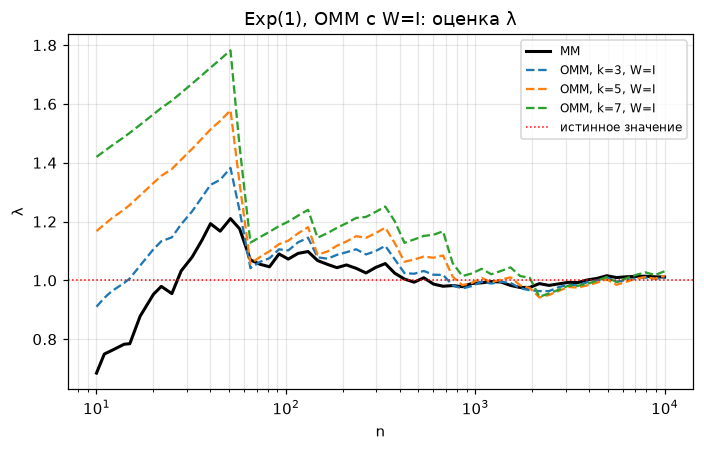

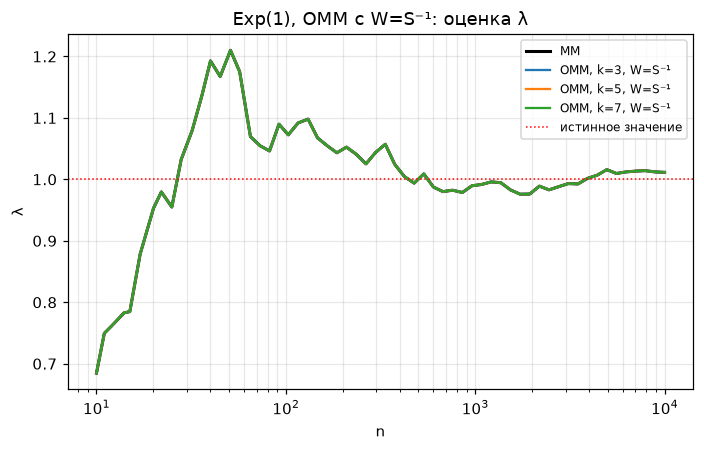

макс. |ОММ(W=S⁻¹) - ММ| по всем n и k: 1.16e-11


In [13]:
plot_trajectories(N_TRAJ, traj_exp, names_I, EXP_PARAMS, EXP_TRUE, 'Exp(1), ОММ с W=I')
plot_trajectories(N_TRAJ, traj_exp, names_opt, EXP_PARAMS, EXP_TRUE, 'Exp(1), ОММ с W=S⁻¹')

diff = max(np.abs(traj_exp[f'ОММ, k={k}, W=S⁻¹'] - traj_exp['ММ']).max() for k in K_LIST)
print(f'макс. |ОММ(W=S⁻¹) - ММ| по всем n и k: {diff:.2e}')

## 3. СКО оценок

Пунктиром — асимптотика; для ММ и ОММ с $W = S^{-1}$ она совпадает с границей Рао–Крамера $\lambda/\sqrt n$.

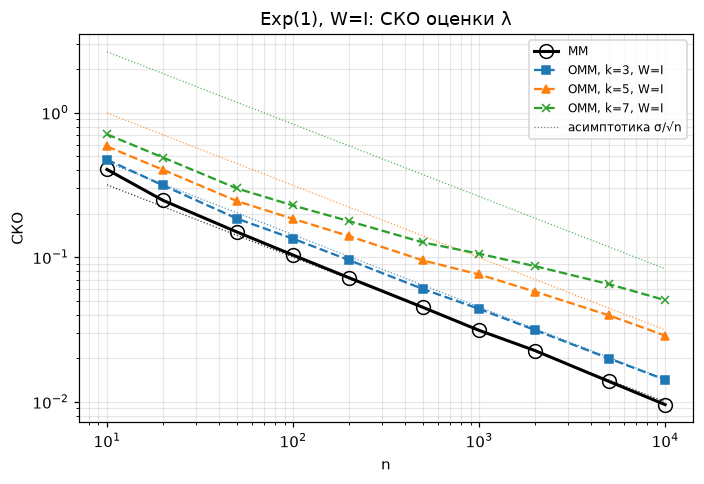

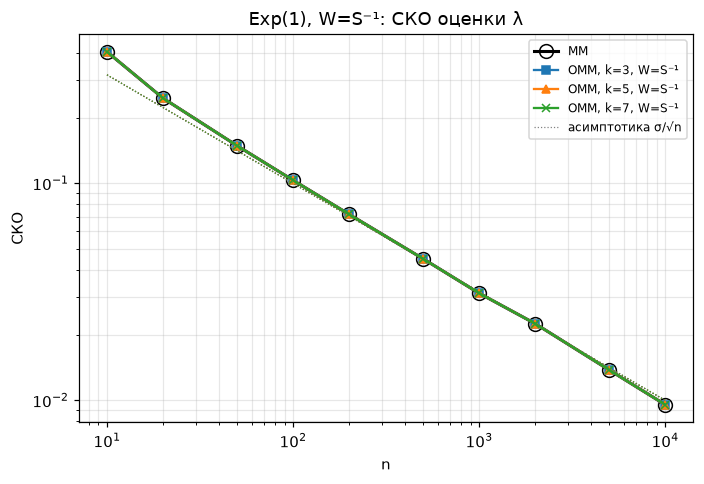

In [14]:
mc_exp = monte_carlo(EXP, lambda rng, size: rng.exponential(1.0, size), N_MC_SIZES, N_MC, SEED + 2)

plot_std(mc_exp, N_MC_SIZES, names_I, EXP_PARAMS, asym_exp, 'Exp(1), W=I')
plot_std(mc_exp, N_MC_SIZES, names_opt, EXP_PARAMS, asym_exp, 'Exp(1), W=S⁻¹')

In [15]:
print_mc_table(mc_exp, N_MC_SIZES, list(STYLE), EXP_PARAMS, EXP_TRUE)


СКО оценки λ (в скобках — смещение)
метод                           10               20               50              100              200              500             1000             2000             5000            10000
ММ                 0.4038 (+0.1261)  0.2470 (+0.0524)  0.1491 (+0.0195)  0.1034 (+0.0123)  0.0720 (+0.0049)  0.0449 (+0.0013)  0.0312 (+0.0008)  0.0226 (+0.0004)  0.0138 (-0.0001)  0.0096 (+0.0004)
ОММ, k=3, W=I      0.4719 (+0.2854)  0.3136 (+0.1502)  0.1846 (+0.0659)  0.1341 (+0.0387)  0.0954 (+0.0188)  0.0602 (+0.0075)  0.0439 (+0.0044)  0.0313 (+0.0015)  0.0199 (+0.0008)  0.0142 (+0.0005)
ОММ, k=5, W=I      0.5835 (+0.5369)  0.4019 (+0.3212)  0.2439 (+0.1680)  0.1840 (+0.1106)  0.1398 (+0.0648)  0.0949 (+0.0328)  0.0759 (+0.0205)  0.0577 (+0.0103)  0.0395 (+0.0049)  0.0287 (+0.0032)
ОММ, k=7, W=I      0.7072 (+0.8190)  0.4886 (+0.5225)  0.2985 (+0.3041)  0.2277 (+0.2162)  0.1774 (+0.1433)  0.1264 (+0.0849)  0.1056 (+0.0596)  0.0866 (+0.0371)  0.0650 (+0.0201)  

### Выводы по экспоненциальному распределению

1. **ММ = ОМП = эффективная оценка.** $\hat\lambda = 1/\bar x$ достигает асимптотической границы Рао–Крамера $\lambda/\sqrt n$; эмпирическое СКО при больших $n$ близко к $1/\sqrt n$.
2. **$W = S^{-1}$ воспроизводит ММ.** Веса оптимального ОММ обнуляют все моменты выше первого ($G^\top S^{-1} \propto (1, 0, \dots, 0)$), поэтому $\hat\lambda_{\mathrm{ОММ}} = \hat\lambda_{\mathrm{ММ}}$ с машинной точностью (разница $\sim 10^{-11}$). Дисперсию по сравнению с ММ снизить **нельзя** — она уже минимальна.
3. **$W = I$ сильно ухудшает оценку.** С ростом $k$ доминирует самый шумный момент: $\sqrt n\,\sigma$ растёт как $1 \to 1{,}43 \to 3{,}14 \to 8{,}31$, плюс появляется заметное положительное смещение при малых и средних $n$.
4. Предлагаемые веса те же — $W = S^{-1}$; для $\mathrm{Exp}$ они не улучшают ММ, но и не портят его, в отличие от $W = I$.

---
# Общие выводы

1. Классический ММ состоятелен, но использует только $p$ моментов и в общем случае неэффективен.
2. ОММ с $W = I$ **не гарантирует** снижения дисперсии: для $U[a, b]$ помогает только одному параметру, для $\mathrm{Exp}$ — заметно ухудшает оценку.
3. **Предлагаемые веса** $W = S^{-1}$ (двухшаговый ОММ) асимптотически оптимальны среди всех квадратичных критериев на заданном наборе моментов. Для $U[a, b]$ они существенно снижают СКО обоих параметров по сравнению с ММ; для $\mathrm{Exp}$ совпадают с ММ (и с ОМП) — улучшить дальше нельзя.
4. С ростом $k$ при оптимальных весах асимптотическая дисперсия не увеличивается (моментное пространство расширяется), а при $W = I$ — часто растёт из-за плохо масштабированных высоких моментов.